<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/heatmap_newDense.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pre-processing

In [30]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [31]:
!ls {path}

auto_test  test  train	val


In [32]:
from torchvision import transforms, datasets

base = path

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [33]:
# only testing
img, label = train[0]
img, label

(tensor([[[-0.5938, -0.5596, -0.5253,  ..., -0.6623, -0.7308, -0.8164],
          [-0.5938, -0.5596, -0.5596,  ..., -0.6794, -0.7650, -0.8507],
          [-0.5767, -0.5767, -0.5424,  ..., -0.6965, -0.7650, -0.8164],
          ...,
          [-1.5014, -1.5014, -1.4672,  ..., -0.7822, -0.7650, -0.7650],
          [-1.5014, -1.5185, -1.4672,  ..., -0.7308, -0.7479, -0.7479],
          [-1.5014, -1.5014, -1.4843,  ..., -0.7137, -0.7137, -0.7479]],
 
         [[-0.4776, -0.4426, -0.4076,  ..., -0.5476, -0.6176, -0.7052],
          [-0.4776, -0.4426, -0.4426,  ..., -0.5651, -0.6527, -0.7402],
          [-0.4601, -0.4601, -0.4251,  ..., -0.5826, -0.6527, -0.7052],
          ...,
          [-1.4055, -1.4055, -1.3704,  ..., -0.6702, -0.6527, -0.6527],
          [-1.4055, -1.4230, -1.3704,  ..., -0.6176, -0.6352, -0.6352],
          [-1.4055, -1.4055, -1.3880,  ..., -0.6001, -0.6001, -0.6352]],
 
         [[-0.2532, -0.2184, -0.1835,  ..., -0.3230, -0.3927, -0.4798],
          [-0.2532, -0.2184,

In [34]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

In [35]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'0': 2286, '1': 1046, '2': 1516, '3': 757, '4': 173}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [36]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 5778 (69.95%) | Classes: {'0': '2286 (39.6%)', '1': '1046 (18.1%)', '2': '1516 (26.2%)', '3': '757 (13.1%)', '4': '173 (3.0%)'}
val   | Total:  826 (10.00%) | Classes: {'0': '328 (39.7%)', '1': '153 (18.5%)', '2': '212 (25.7%)', '3': '106 (12.8%)', '4': '27 (3.3%)'}
test  | Total: 1656 (20.05%) | Classes: {'0': '639 (38.6%)', '1': '296 (17.9%)', '2': '447 (27.0%)', '3': '223 (13.5%)', '4': '51 (3.1%)'}


In [37]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [38]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 5778


In [39]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test, batch_size=32, shuffle=False, num_workers=4)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([0, 3, 0, 0, 3, 3, 3, 1, 0, 2])


In [40]:
import cv2
import numpy as np
from PIL import Image

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True, num_workers=4)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=4)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=4)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 224, 224])
train: 5778 | val: 826 | test: 1656


### Why does the image have 3 channels instead of 1?

Even though your knee X-ray dataset is grayscale, your image tensor shape shows `3` channels because of this line in your pre-processing transforms:

```python
transforms.Grayscale(3)
```

* **Channel Duplication:** This transform takes the single-channel grayscale image and replicates it across 3 identical channels ($R = G = B$).
* **Pre-trained Model Compatibility:** Transfer learning backbones (such as ResNet, EfficientNet, etc.) are pre-trained on ImageNet (RGB datasets) and strictly require a 3-channel input shape. Replicating the channels allows you to use these models without needing to modify their first convolutional layer.

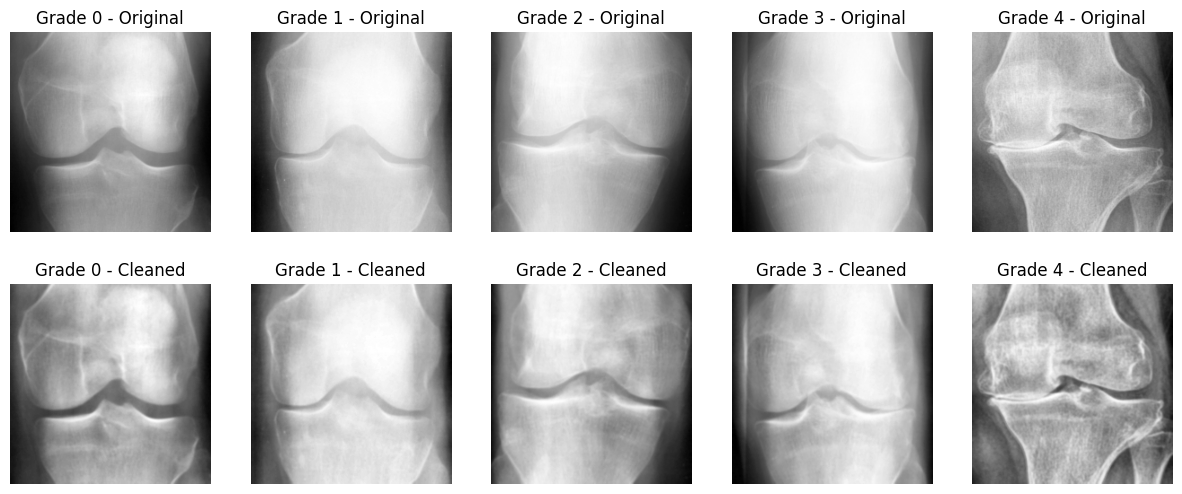

In [41]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

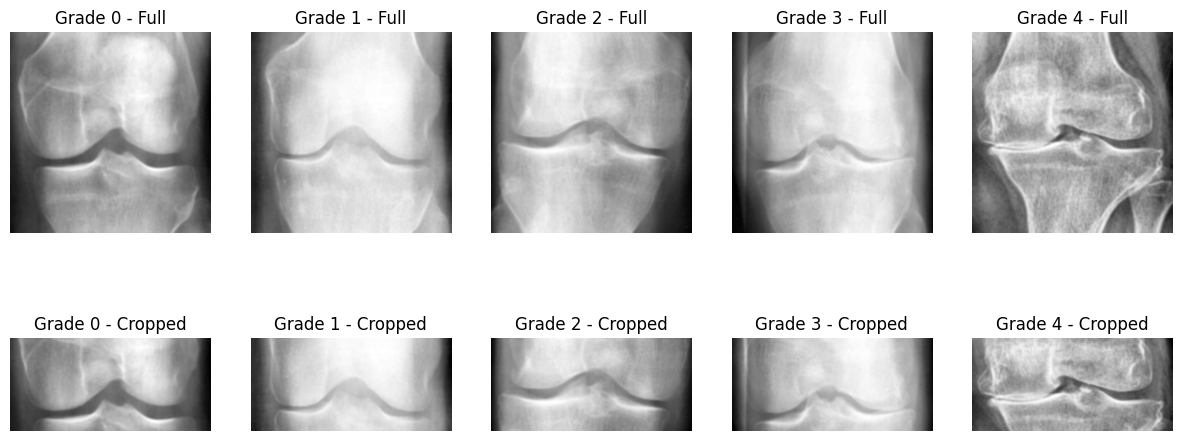

In [42]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cropped"); axes[1][k].axis("off")
plt.show()


batch shape: torch.Size([32, 3, 104, 224])

Total images: 8260 | joint found: 7939 | fallback crop: 321
Joint far from the usual position (shift was clipped): 173
  Grade 0: joint not found in 58 of 3253 (2%)
  Grade 1: joint not found in 24 of 1495 (2%)
  Grade 2: joint not found in 78 of 2175 (4%)
  Grade 3: joint not found in 106 of 1086 (10%)
  Grade 4: joint not found in 55 of 251 (22%)
When the joint is found, the crop always covers rows 88 to 160


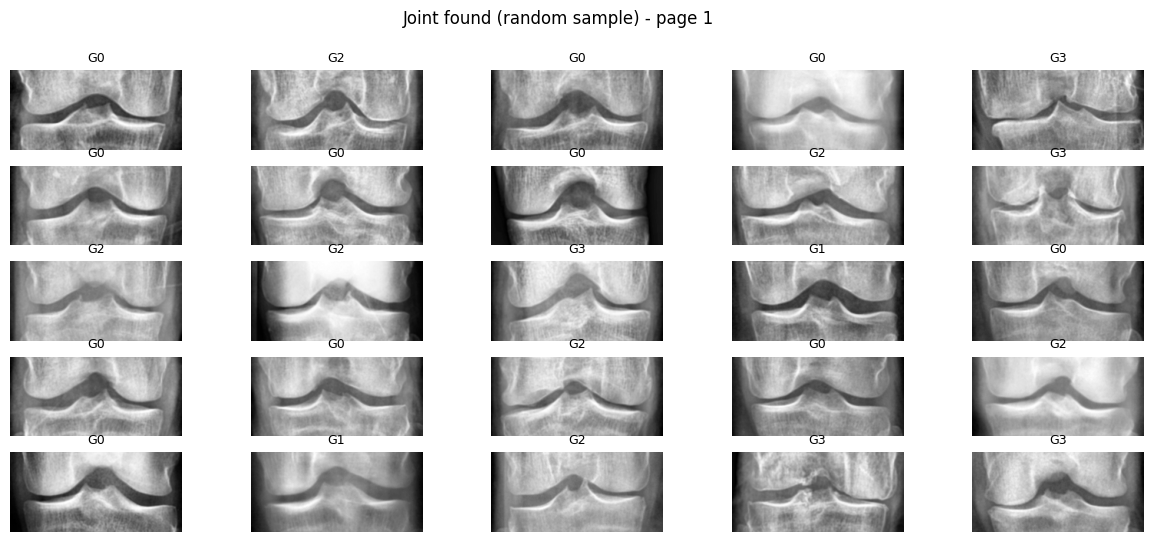

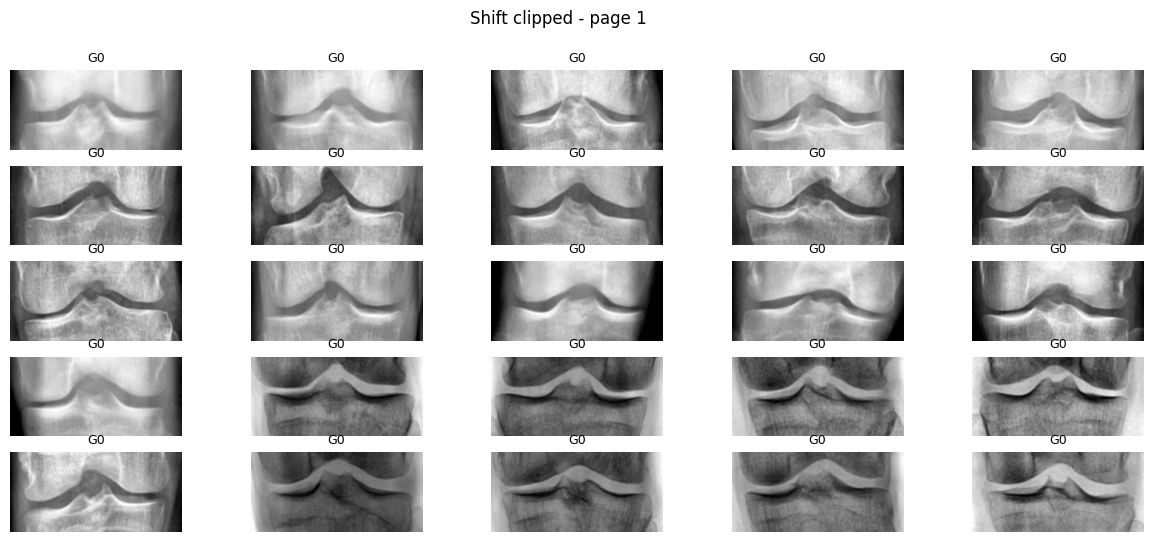

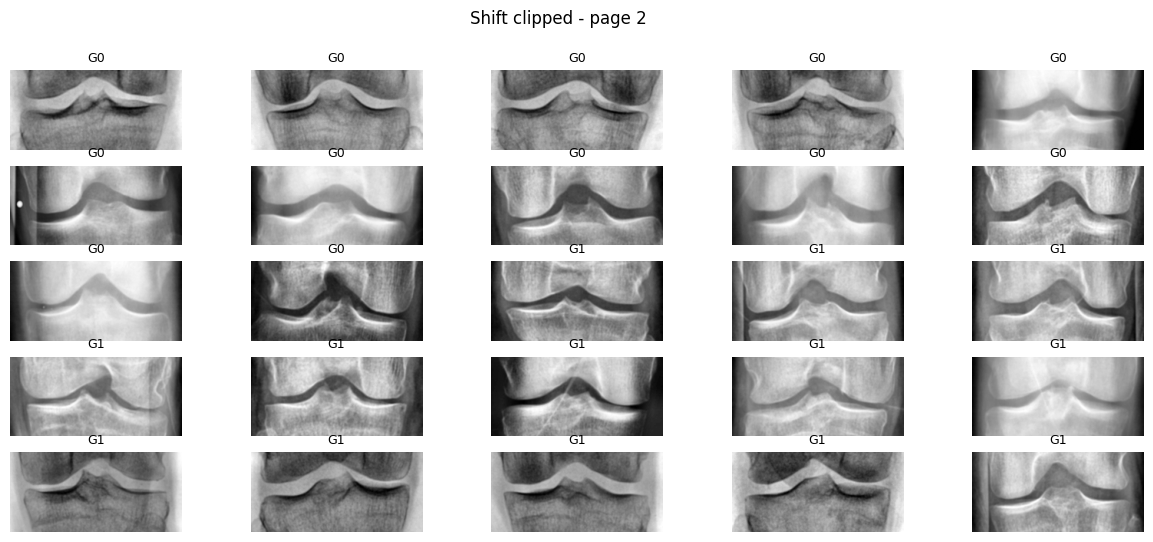

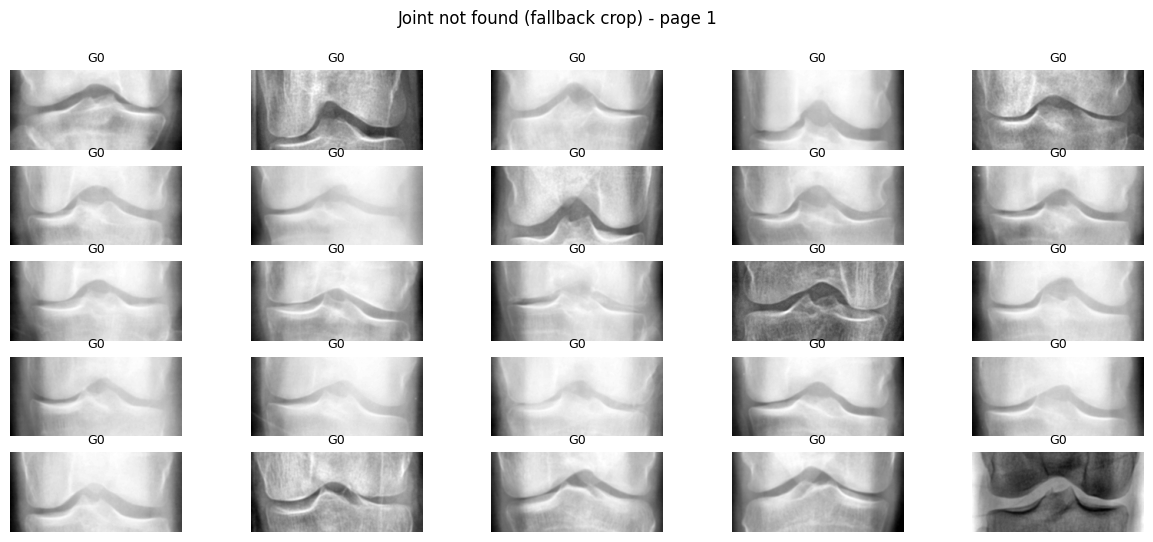

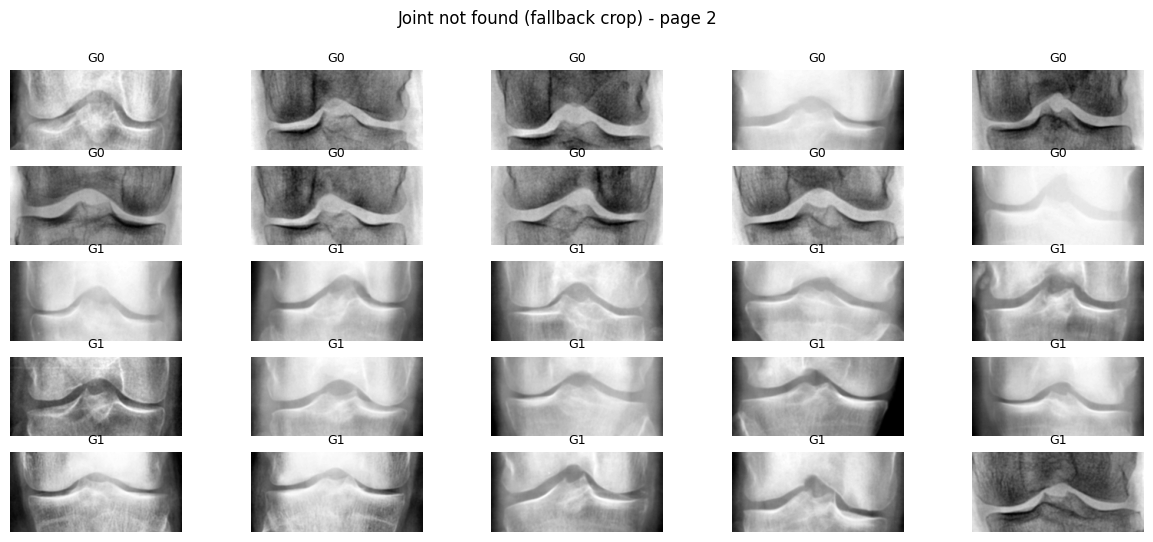

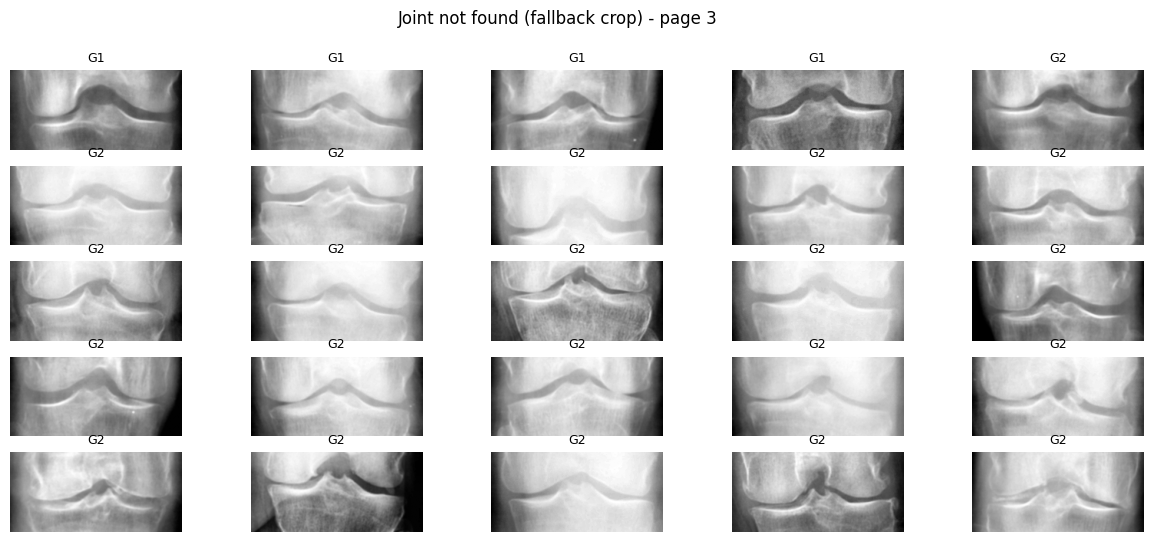

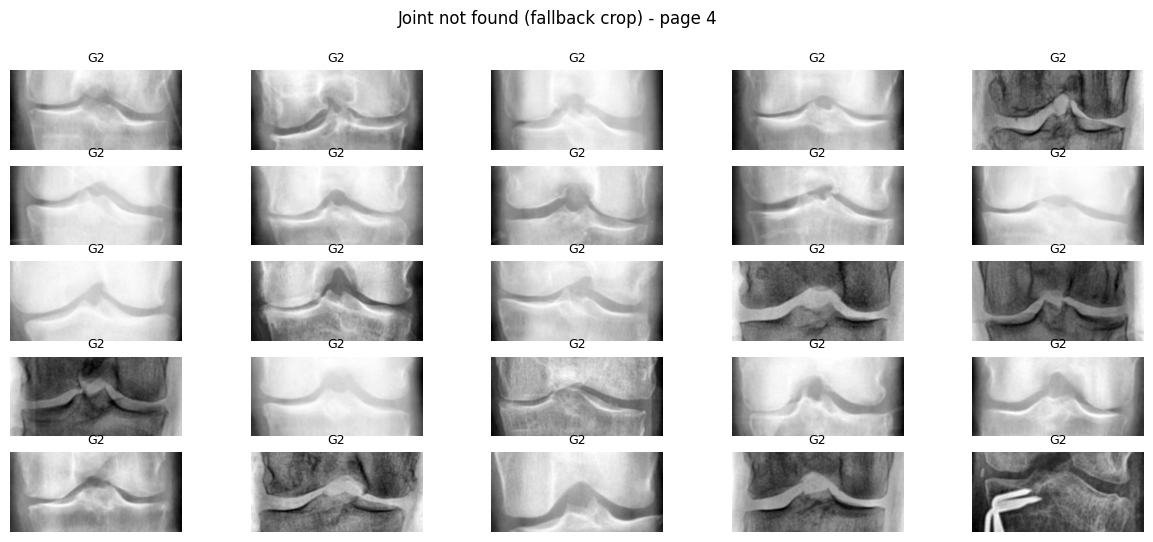

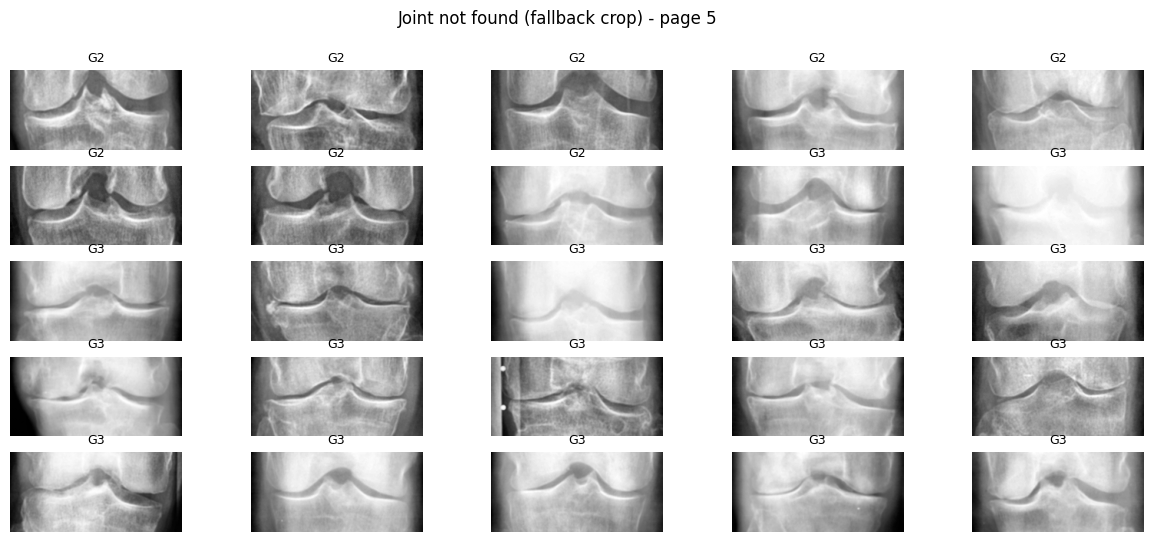

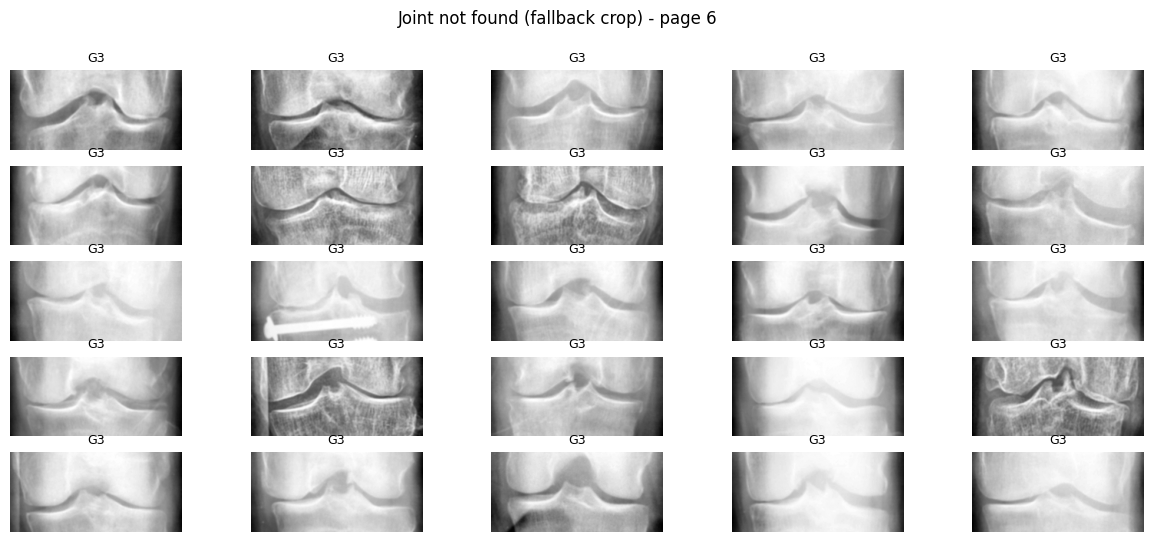

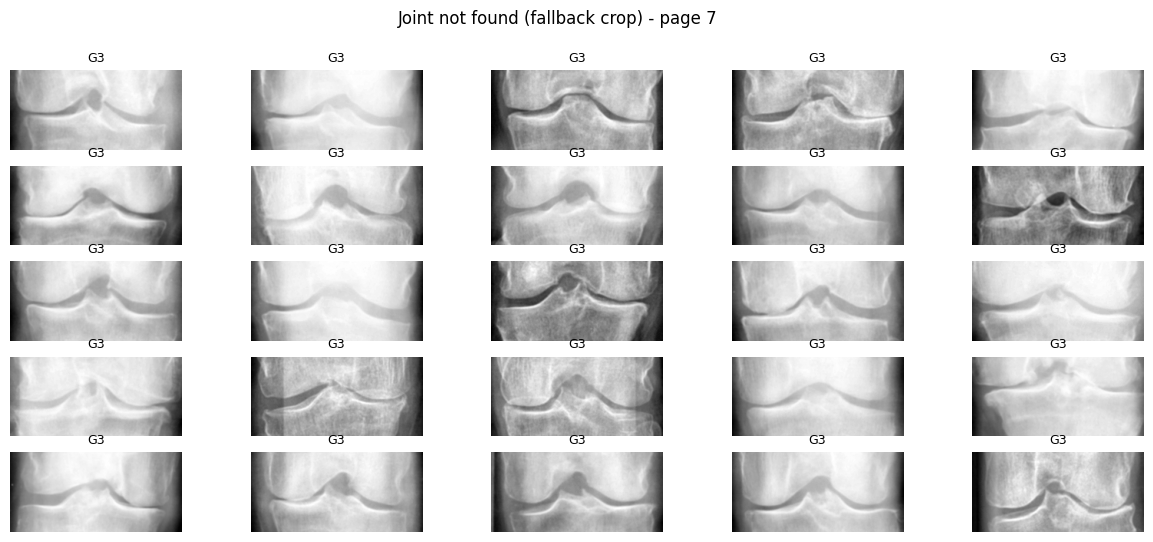

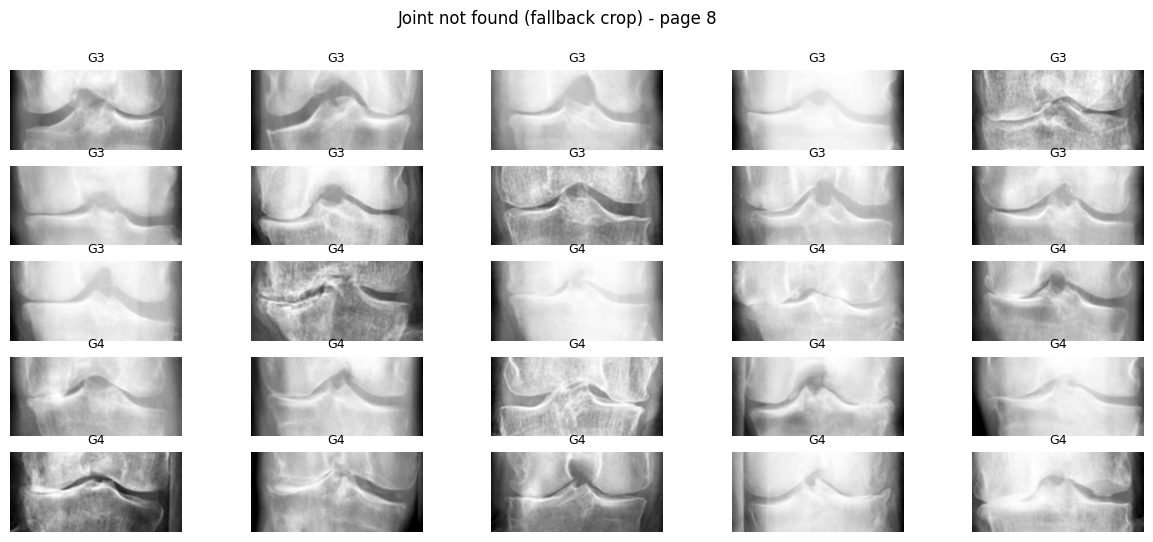

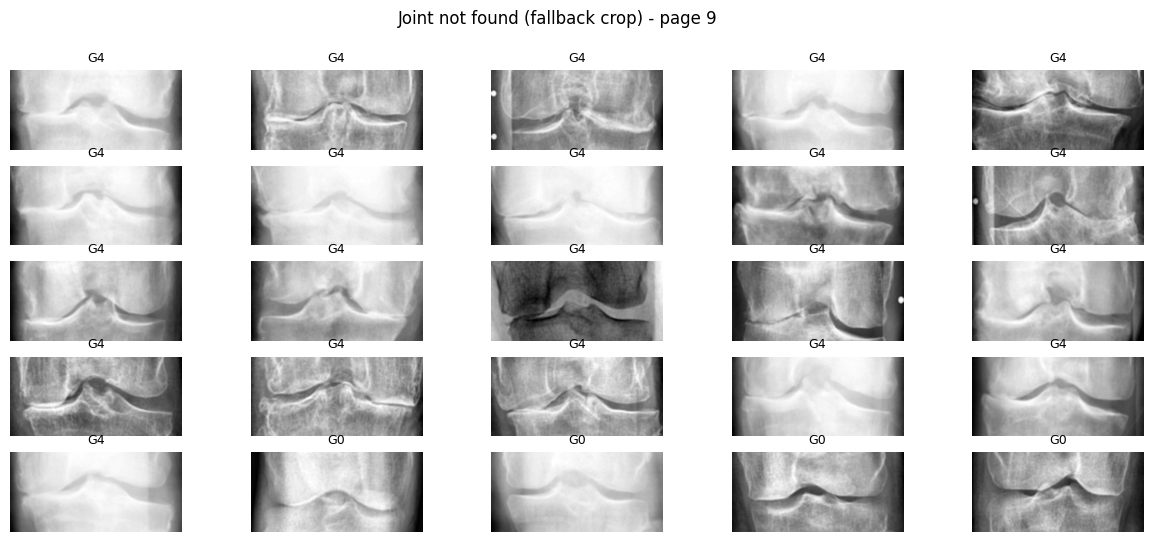

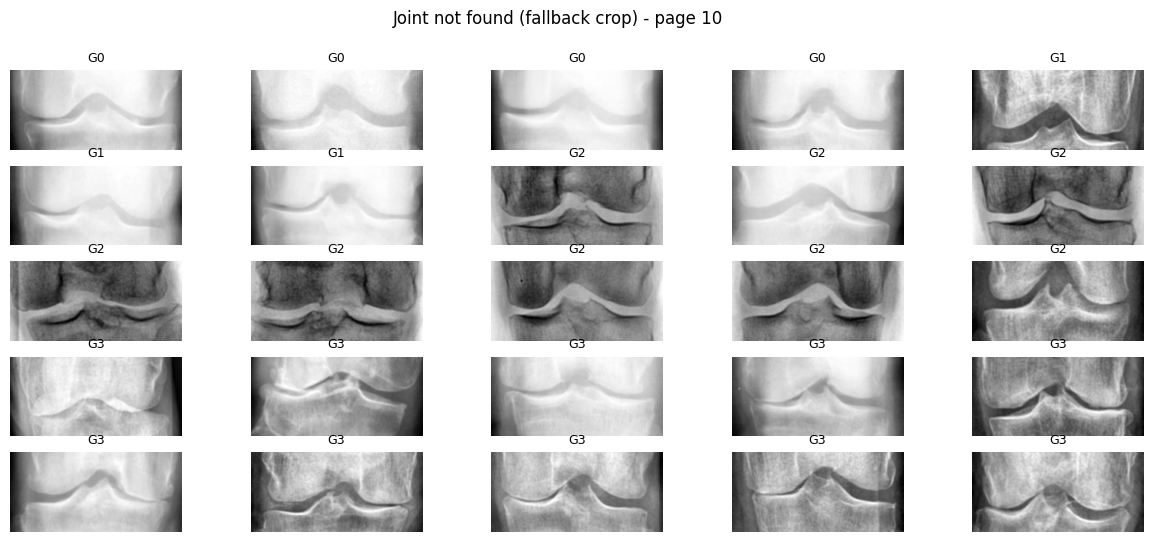

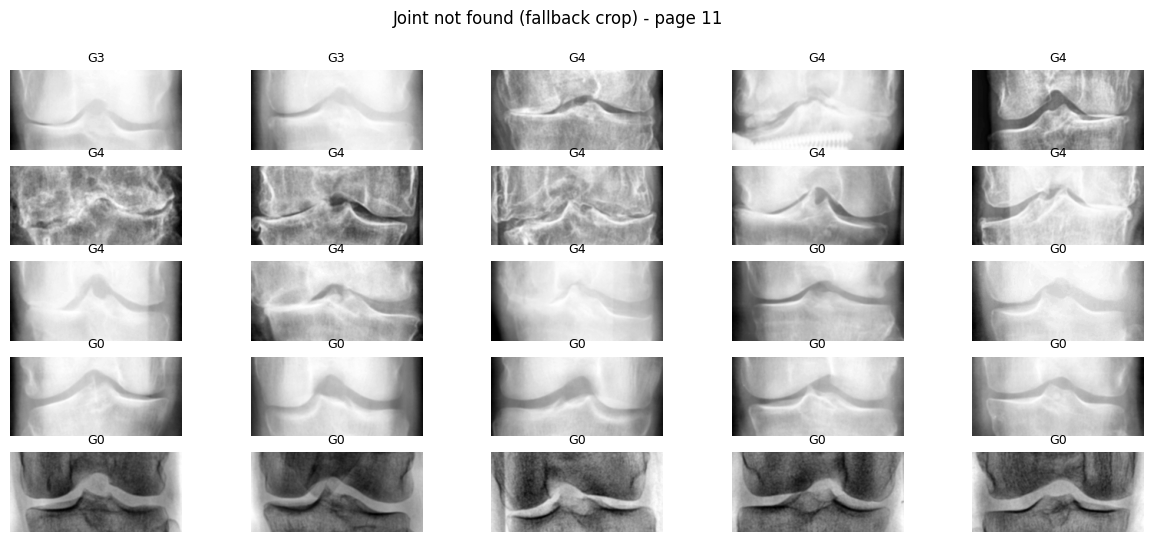

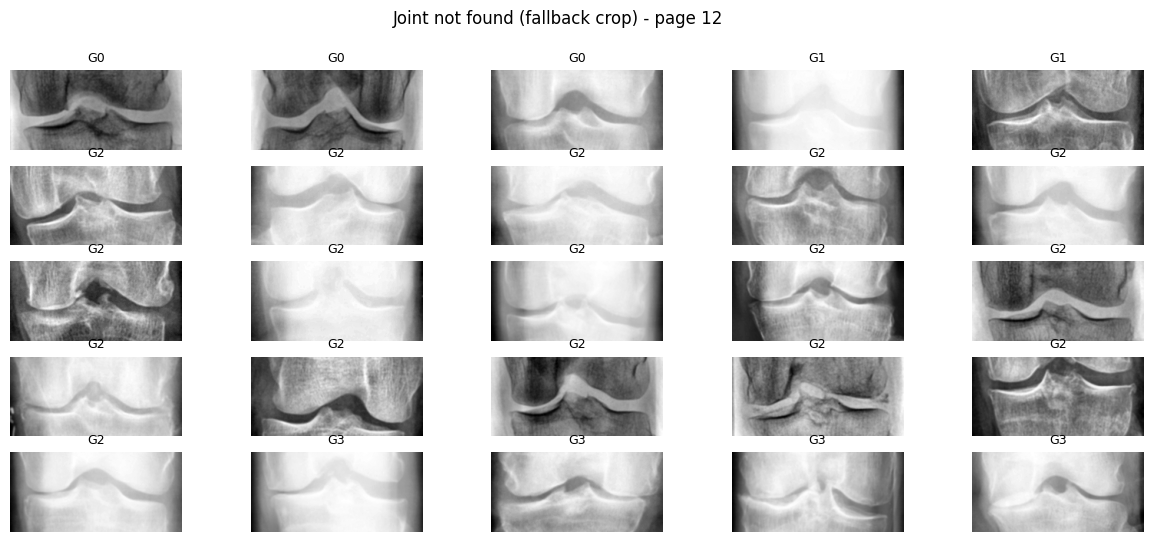

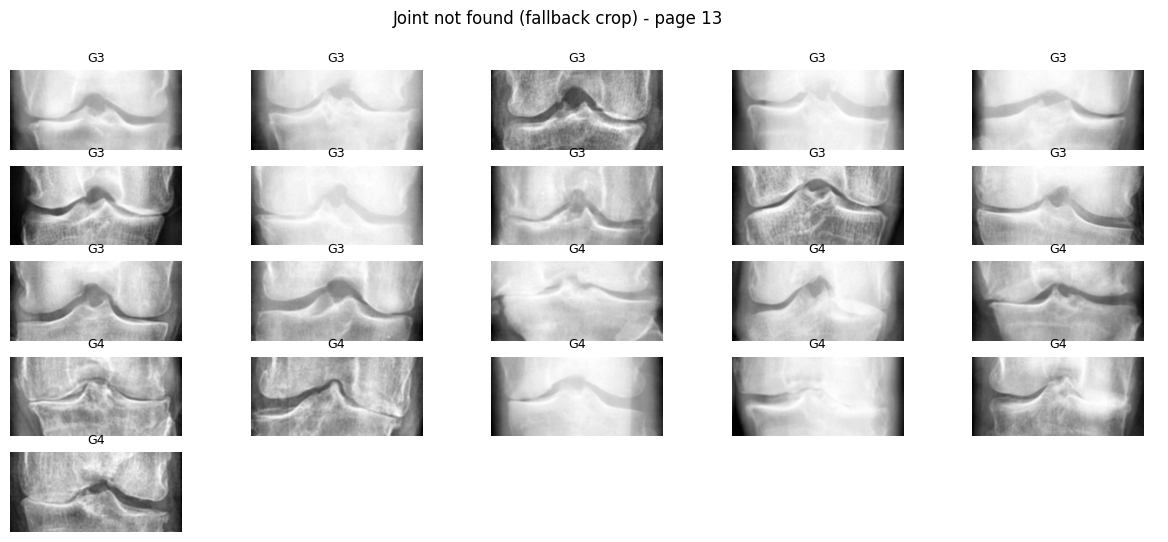

In [43]:
# ======================= NEW: joint-aware crop (single cell) =======================
# Run this AFTER the original cells (it needs `base` and the original `Denoise` class).
# Nothing from the original pipeline is changed: every new object ends with " ".
import random
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Settings (change values here only) ----------
SIZE = 224
WINDOW_H = 104        # crop height (same as the 60/60 crop: 224 - 60 - 60)
PRIOR_ROW = 124       # most likely joint row (measured median 0.554 x 224)
MAX_SHIFT = 16        # max shift allowed from PRIOR_ROW (protects against a wrong detection)
FALLBACK_ROW = 124    # crop center when no joint is found (use 112 for the exact 60/60 crop)
RUN_CHECK = True      # True = scan all images and show examples, False = skip the check


# ---------- 1) Find the joint space ----------
def find_joint_row(gray, lo=0.40, hi=0.70, min_prom=4):
    """Return the row of the joint space, or None if it is not found."""
    H, W = gray.shape
    cols = gray[:, int(W * 0.25):int(W * 0.75)].astype(np.float32)   # central columns only
    prof = gaussian_filter1d(cols.mean(axis=1), sigma=H * 0.02)      # smoothed brightness of each row
    a, b = int(H * lo), int(H * hi)                                  # search only where the joint usually is
    peaks, props = find_peaks(-prof[a:b], prominence=min_prom)       # darkest valley = joint gap
    if len(peaks) == 0:
        return None
    return a + int(peaks[np.argmax(props["prominences"])])


# ---------- 2) Denoise + crop around the joint ----------
class SmartCrop:
    def __init__(self):
        self.denoise = Denoise()                                     # the original Denoise class (unchanged)
    def __call__(self, img):
        img = img.convert("L").resize((SIZE, SIZE))
        row = find_joint_row(np.array(img))                          # detect on the raw image
        if row is None:
            center = FALLBACK_ROW                                    # not found: crop around the most likely position
        else:                                                        # found: center on it, with a limited shift
            center = int(np.clip(row, PRIOR_ROW - MAX_SHIFT, PRIOR_ROW + MAX_SHIFT))
        top = center - WINDOW_H // 2
        return self.denoise(img).crop((0, top, SIZE, top + WINDOW_H))   # 224 x 104


# ---------- 3) Same pipeline as the original, but SmartCrop replaces Denoise + Resize ----------
# No Resize here: SmartCrop already returns the final 224 x 104 image.
tf = transforms.Compose([                                      # val / test (no augmentation)
    SmartCrop(),
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_tf  = transforms.Compose([                                # train (with augmentation)
    SmartCrop(),
    transforms.Grayscale(3),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train  = datasets.ImageFolder(f"{base}/train", transform=train_tf )
val    = datasets.ImageFolder(f"{base}/val",   transform=tf )
test   = datasets.ImageFolder(f"{base}/test",  transform=tf )

train_loader  = DataLoader(train , batch_size=32, shuffle=True,  num_workers=2)
val_loader    = DataLoader(val ,   batch_size=32, shuffle=False, num_workers=2)
test_loader   = DataLoader(test ,  batch_size=32, shuffle=False, num_workers=2)
print("batch shape:", next(iter(train_loader ))[0].shape)       # expected [32, 3, 104, 224]


# ---------- 4) Check (a bit slow; set RUN_CHECK = False once you are done) ----------
if RUN_CHECK:
    info = []                                        # (grade, joint row or None, image path)
    for ds in (train , val , test ):
        for p, g in ds.samples:
            gray = np.array(Image.open(p).convert("L").resize((SIZE, SIZE)))
            info.append((g, find_joint_row(gray), p))
    found = [x for x in info if x[1] is not None]
    fallback = [x for x in info if x[1] is None]
    clipped = [x for x in found if abs(x[1] - PRIOR_ROW) > MAX_SHIFT]

    print(f"\nTotal images: {len(info)} | joint found: {len(found)} | fallback crop: {len(fallback)}")
    print(f"Joint far from the usual position (shift was clipped): {len(clipped)}")
    for k in range(5):
        n = sum(1 for x in info if x[0] == k)
        f = sum(1 for x in fallback if x[0] == k)
        print(f"  Grade {k}: joint not found in {f} of {n} ({100 * f / n:.0f}%)")
    lo_c = PRIOR_ROW + MAX_SHIFT - WINDOW_H // 2
    hi_c = PRIOR_ROW - MAX_SHIFT + WINDOW_H // 2
    print(f"When the joint is found, the crop always covers rows {lo_c} to {hi_c}")

    sc = SmartCrop()
    def show_pages(items, title, max_pages=20):
        for pg in range(min(max_pages, -(-len(items) // 25))):
            fig, axes = plt.subplots(5, 5, figsize=(15, 6))
            for ax in axes.ravel(): ax.axis("off")
            for ax, x in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
                ax.imshow(sc(Image.open(x[2])), cmap="gray")         # same image the model sees
                ax.set_title(f"G{x[0]}", fontsize=9)
            fig.suptitle(f"{title} - page {pg + 1}")
            plt.show()

    random.seed(1)
    show_pages(random.sample(found, 25), "Joint found (random sample)", 1)
    show_pages(clipped, "Shift clipped", 2)
    show_pages(fallback, "Joint not found (fallback crop)")


# Reproducibility & Agnostic Code

In [44]:
# Reproducibility (paper, Section 2.9: seed = 42, cuDNN determinism enabled)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (DenseNet-201)

## Training

In [45]:
def train_step(model,
               data_loader,
               loss_fn,
               optm,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss.item() * input.size(0)
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optm.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optm.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [46]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [47]:
import numpy as np
from sklearn.metrics import f1_score, cohen_kappa_score

@torch.no_grad()
def get_preds(loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.extend(logits_to_grade(model(x.to(device))).cpu().numpy())
        labels.extend(y.numpy())
    return np.array(labels), np.array(preds)

def val_macro_f1():
    y, p = get_preds(val_loader)
    return f1_score(y, p, average="macro")

def val_qwk():
    y, p = get_preds(val_loader)
    return cohen_kappa_score(y, p, weights="quadratic")

In [48]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [49]:
def run_epoch(loader, optimizer=None, freeze_backbone=False):
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits_to_grade(out) == y).sum().item()   # was out.argmax(1)
            n += len(y)
    return total_loss / n, 100 * correct / n

In [50]:
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score

def test_report():
    te_loss, te_acc = run_epoch(test_loader)
    y, p = get_preds(test_loader)
    print(f"TEST loss {te_loss:.3f} | TEST acc {te_acc:.2f}% | "
          f"MAE {np.abs(y-p).mean():.3f} | QWK {cohen_kappa_score(y, p, weights='quadratic'):.4f}")
    print(classification_report(y, p, zero_division=0))
    print(confusion_matrix(y, p))

In [51]:
import copy

def fit(optimizer, epochs, freeze_backbone, name):
    best_score, best_state = 0, None

    for e in range(epochs):
        tr_loss, tr_acc = run_epoch(train_loader, optimizer, freeze_backbone)
        va_loss, va_acc = run_epoch(val_loader)

        qwk = val_qwk()
        if qwk > best_score:
          best_score, best_state = qwk, copy.deepcopy(model.state_dict())

        print(f"[{name}] Epoch {e+1:02d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.1f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1f} | "
              f"val qwk {qwk:.3f}")

    model.load_state_dict(best_state)
    print(f"Restored best epoch (val qwk {best_score:.3f})")

In [52]:
import torch, torch.nn as nn, torch.nn.functional as F

NUM_CLASSES = 5
K = NUM_CLASSES - 1          # 4 binary thresholds

class CoralHead(nn.Module):
    """One shared score + (K) ordered thresholds -> K logits."""
    def __init__(self, in_features, num_classes=NUM_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_features, 1, bias=False)
        # descending init so P(y>0) > P(y>1) > ...
        self.bias = nn.Parameter(torch.linspace(1.5, -1.5, num_classes - 1))
    def forward(self, x):
        return self.fc(x) + self.bias            # (B, K)

def ordinal_loss(logits, y, class_weights=None):
    levels = (y.unsqueeze(1) > torch.arange(K, device=y.device)).float()   # (B, K)
    loss = F.binary_cross_entropy_with_logits(logits, levels, reduction="none").sum(1)
    if class_weights is not None:                # keep your imbalance handling
        loss = loss * class_weights[y]
    return loss.mean()

def logits_to_grade(logits):
    return (torch.sigmoid(logits) > 0.5).sum(1)  # 0..4

## PHASE 1 -- freeze DenseNet, train only the new layer, 10 epochs

In [53]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the pre-trained DenseNet model
model = models.densenet201(weights=models.DenseNet201_Weights.DEFAULT)

# 2. Freeze all backbone parameters first
for param in model.parameters():
    param.requires_grad = False

# 3. Replace the classifier. Newly created layers have requires_grad=True by default.
num_ftrs = model.classifier.in_features
model.classifier = CoralHead(num_ftrs)
model = model.to(device)

# 4. Setup loss function and optimizer
# Pass only the classifier parameters to the optimizer for Phase 1
cw = class_weights.to(device)
loss_fn = lambda out, y: ordinal_loss(out, y, cw)
optm = optim.Adam(model.classifier.parameters(), lr=0.001)

acc_fn = accuracy_fn

# Run training Phase 1
fit(optm, epochs=10, freeze_backbone=True, name="Phase 1: frozen")

print("\n--- Test result after Phase 1 ---")
test_report()

[Phase 1: frozen] Epoch 01/10 | train loss 1.843 acc 29.8 | val loss 1.620 acc 35.4 | val qwk 0.546
[Phase 1: frozen] Epoch 02/10 | train loss 1.613 acc 35.7 | val loss 1.561 acc 35.0 | val qwk 0.555
[Phase 1: frozen] Epoch 03/10 | train loss 1.536 acc 37.3 | val loss 1.634 acc 41.5 | val qwk 0.579
[Phase 1: frozen] Epoch 04/10 | train loss 1.518 acc 37.9 | val loss 1.506 acc 38.5 | val qwk 0.592
[Phase 1: frozen] Epoch 05/10 | train loss 1.494 acc 37.6 | val loss 1.512 acc 33.7 | val qwk 0.554
[Phase 1: frozen] Epoch 06/10 | train loss 1.462 acc 37.9 | val loss 1.522 acc 40.3 | val qwk 0.598
[Phase 1: frozen] Epoch 07/10 | train loss 1.452 acc 39.1 | val loss 1.486 acc 35.1 | val qwk 0.565
[Phase 1: frozen] Epoch 08/10 | train loss 1.423 acc 38.7 | val loss 1.468 acc 37.0 | val qwk 0.579
[Phase 1: frozen] Epoch 09/10 | train loss 1.411 acc 38.5 | val loss 1.476 acc 34.9 | val qwk 0.573
[Phase 1: frozen] Epoch 10/10 | train loss 1.411 acc 38.8 | val loss 1.484 acc 42.3 | val qwk 0.614


## PHASE 2 -- unfreeze everything, fine-tune, lr 0.001, 20 more epochs

In [54]:
for p in model.parameters():
    p.requires_grad = True

# NEW optimizer covering the whole network (the Phase 1 one only had the classifier)
optm = optim.Adam(model.parameters(), lr=0.00001)

fit(optm, epochs=20, freeze_backbone=False, name="Phase 2: fine-tune")

print("\n--- Final test result after fine-tuning ---")
test_report()

[Phase 2: fine-tune] Epoch 01/20 | train loss 2.601 acc 16.7 | val loss 2.002 acc 22.6 | val qwk 0.314
[Phase 2: fine-tune] Epoch 02/20 | train loss 1.597 acc 31.3 | val loss 1.449 acc 35.1 | val qwk 0.552
[Phase 2: fine-tune] Epoch 03/20 | train loss 1.359 acc 38.8 | val loss 1.333 acc 39.5 | val qwk 0.618
[Phase 2: fine-tune] Epoch 04/20 | train loss 1.268 acc 42.6 | val loss 1.327 acc 42.6 | val qwk 0.640
[Phase 2: fine-tune] Epoch 05/20 | train loss 1.225 acc 45.2 | val loss 1.303 acc 42.5 | val qwk 0.649
[Phase 2: fine-tune] Epoch 06/20 | train loss 1.166 acc 46.0 | val loss 1.267 acc 44.4 | val qwk 0.669
[Phase 2: fine-tune] Epoch 07/20 | train loss 1.144 acc 47.6 | val loss 1.229 acc 47.7 | val qwk 0.683
[Phase 2: fine-tune] Epoch 08/20 | train loss 1.113 acc 49.9 | val loss 1.251 acc 49.0 | val qwk 0.682
[Phase 2: fine-tune] Epoch 09/20 | train loss 1.095 acc 49.8 | val loss 1.243 acc 45.8 | val qwk 0.671
[Phase 2: fine-tune] Epoch 10/20 | train loss 1.076 acc 50.7 | val loss 1

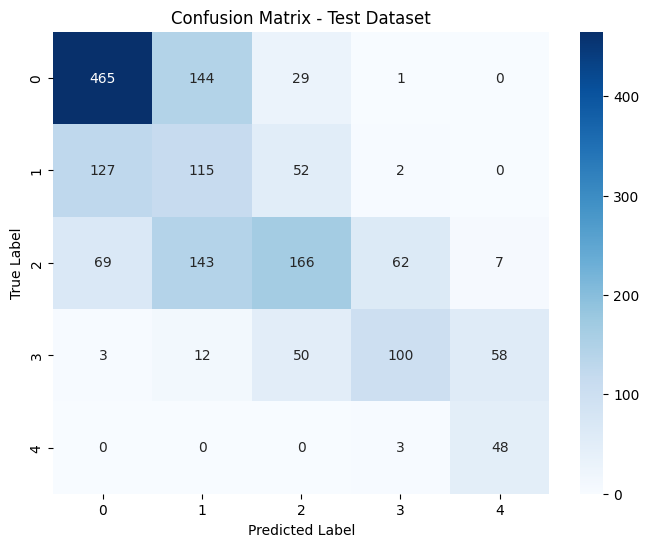

In [55]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get true and predicted grades for the test set
all_labels, all_preds = get_preds(test_loader)

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)
class_names = train.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [56]:
from sklearn.metrics import cohen_kappa_score

all_labels, all_preds = get_preds(test_loader)

qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}")

Quadratic Weighted Kappa (QWK): 0.7668


In [57]:
!pip install grad-cam

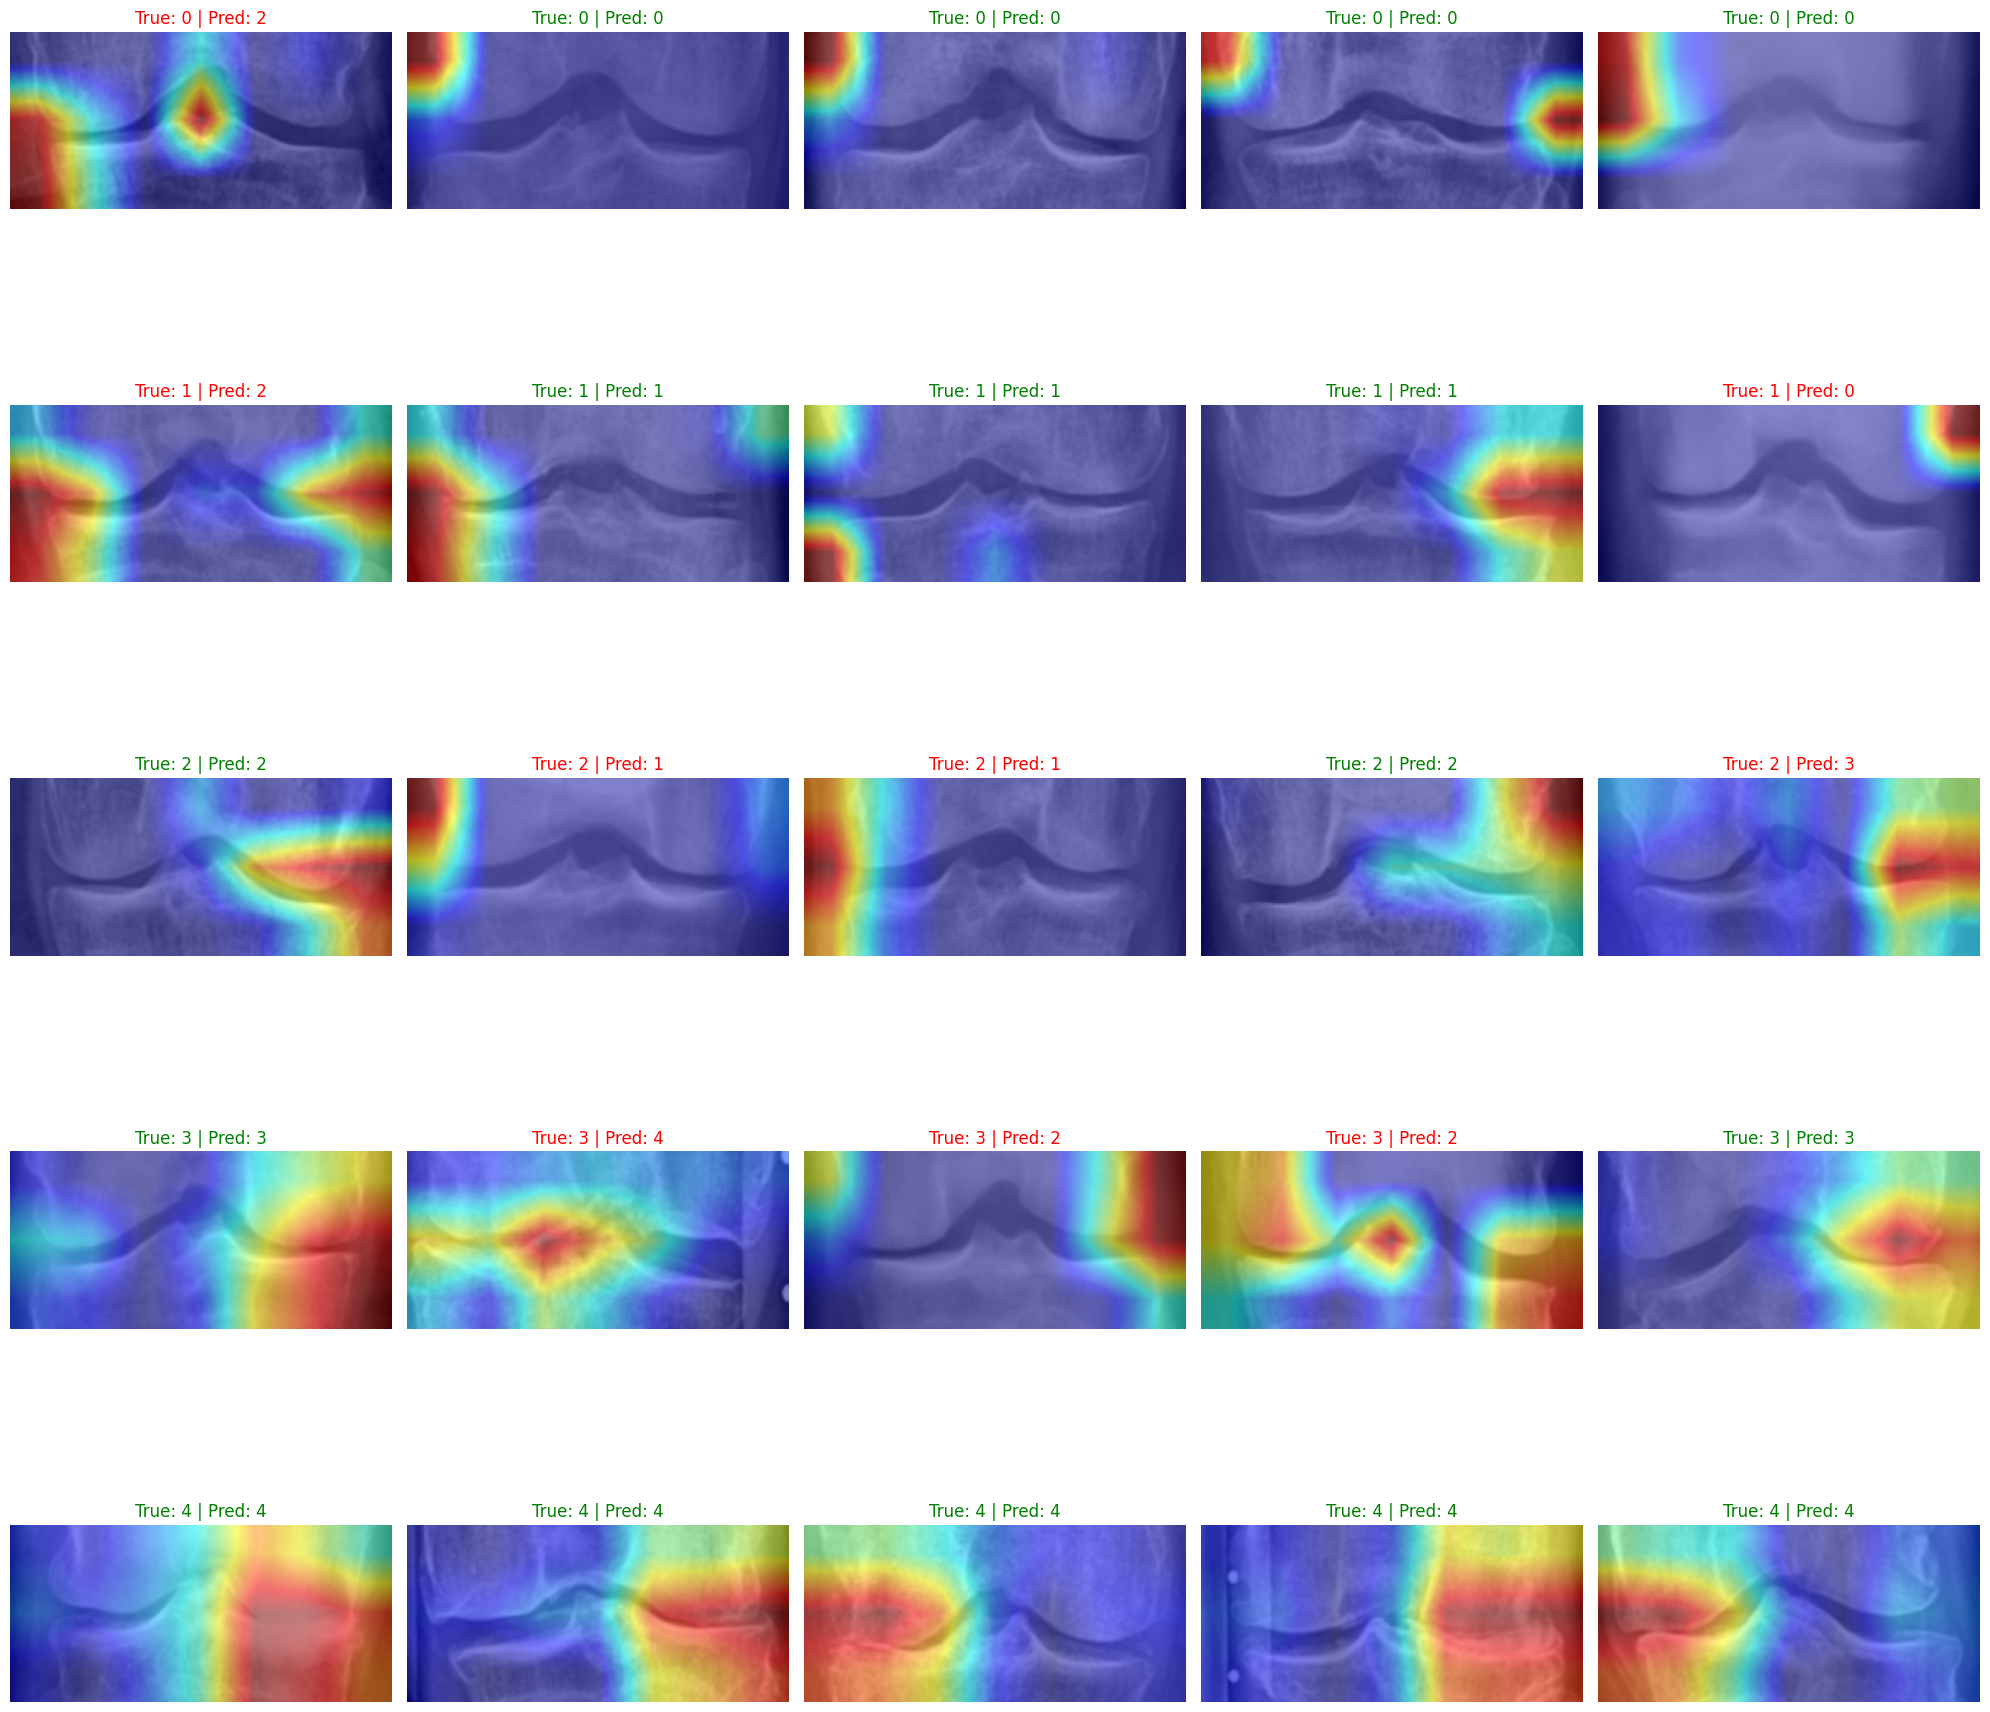

In [58]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Target for ordinal model: expected grade = sum of the 4 threshold probabilities
class SeverityTarget:
    def __call__(self, model_output):
        return torch.sigmoid(model_output).sum()

# Group test indices by their true label
label_to_indices = {i: [] for i in range(5)}
for idx in range(len(test)):
    _, label = test[idx]
    label_to_indices[label].append(idx)

# Select 5 random images for each grade
selected_indices = []
for i in range(5):
    samples = random.sample(label_to_indices[i], min(5, len(label_to_indices[i])))
    selected_indices.extend(samples)

# DenseNet201 target layer for Grad-CAM
# (try model.features.denseblock3 here if you want a higher-resolution heatmap)
target_layers = [model.features[-1]]

# Initialize Grad-CAM
cam = GradCAM(model=model, target_layers=target_layers)

fig, axes = plt.subplots(5, 5, figsize=(20, 20))
axes = axes.flatten()

model.eval()

for i, idx in enumerate(selected_indices):
    img_tensor, true_label = test[idx]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    # Get prediction (ordinal decoding instead of argmax)
    with torch.no_grad():
        output = model(input_tensor)
        pred_label = logits_to_grade(output).item()

    # Generate heatmap for the model's overall severity score
    grayscale_cam = cam(input_tensor=input_tensor, targets=[SeverityTarget()])
    grayscale_cam = grayscale_cam[0, :]

    # Un-normalize the image for visualization
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1)

    # Overlay heatmap on image
    visualization = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    # Plot
    ax = axes[i]
    ax.imshow(visualization)
    title_color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f"True: {true_label} | Pred: {pred_label}", color=title_color)
    ax.axis('off')

plt.tight_layout()
plt.show()